# Анализ зависимости между грузооборотом порта Сантуса и населением фавел

## О проекте
Развитие портовых городов неизбежно порождает городские конфликты. Как отмечается в современных исследованиях, разрастание площади порта и увеличение грузооборота приводит к отчуждению территории города в пользу портово-логистической инфраструктуры. 

Город Сантус (Бразилия), где расположен крупнейший порт страны, представляет собой яркий пример такого процесса. С ростом порта создаются физические барьеры, отделяющие его от города, такие как Avenida Perimetral, а малообеспеченные слои общества вытесняются на периферию. 

Цель данного проекта с помощью языка Python (библиотеки NumPy и Matplotlib) проанализировать, как динамика развития порта соотносится с ростом населения в городских фавелах, и выявить силу этой зависимости на основе количественных данных.


## Источники данных и подготовка датасета
Для анализа использовались официальные статистические данные Бразилии за 2000, 2010 и 2022 годы. На основе первичных материалов был сформирован единый датасет `santos_data.txt`.

**Первичные источники:**
1. **ANTAQ** (Agência Nacional de Transportes Aquaviários) — данные о грузообороте и контейнерообороте порта Сантус (на основе отчетов о движении грузов, файлы `Movimentacao`).
2. **IBGE** (Instituto Brasileiro de Geografia e Estatística) — данные переписей населения о фавелах (субнормальных агломерациях) и доходах. Были использованы следующие таблицы:
   - *Domicílios particulares ocupados em aglomerados subnormais e Média de moradores* (домохозяйства и средний размер семьи в фавелах);
   - *População residente em favelas e comunidades urbanas* (население фавел);
   - *Количество фавел и городских поселений по муниципалитетам*;
   - *Медианный ежемесячный номинальный доход лиц в возрасте 10 лет и старше*;
   - *Таблица 1427 - Постоянные частные домохозяйства по классам номинального ежемесячного дохода*.

**Итоговый датасет `santos_data.txt` содержит следующие показатели по годам:**
- Год (2000, 2010, 2022)
- Грузооборот порта (млн тонн)
- Контейнерооборот (млн TEU)
- Население фавел (чел.)
- Домохозяйства в фавелах (ед.)
- Средний размер домохозяйства (чел.)
- Кол-во фавел (ед.)

In [110]:
import numpy as np
import matplotlib.pyplot as plt

In [111]:
data = np.loadtxt('santos-favelas-port-analysis/data/santos_data.txt')
anos = data[:, 0]   
pop = data[:, 3] 
dom = data[:, 4]        
media_dom = data[:, 5]  
wage = data[:, 7]      
carga = data[:, 1]
cont = data[:, 2]




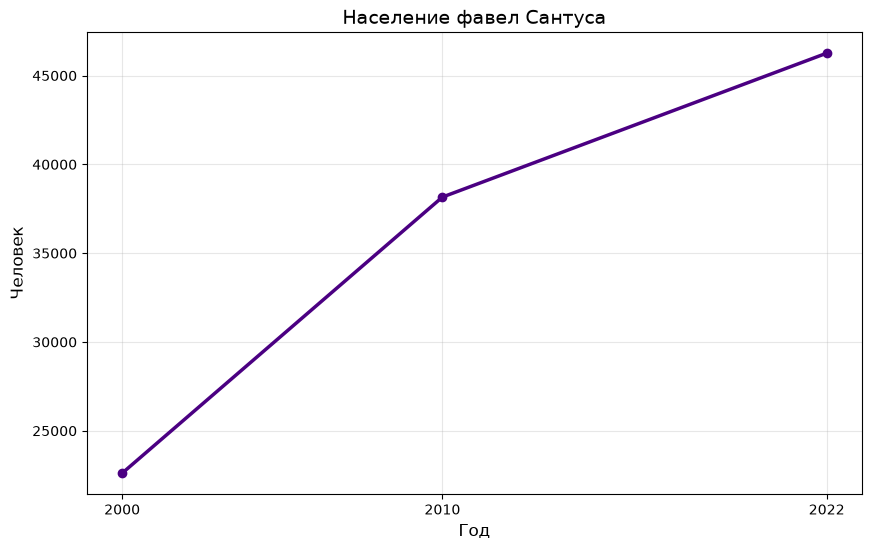

In [112]:

plt.figure(figsize=(10, 6))
plt.plot(anos, pop, marker='o', color='indigo',linewidth=2.5)
plt.title('Население фавел Сантуса', fontsize=14)
plt.xlabel('Год', fontsize=12)
plt.ylabel('Человек', fontsize=12)
plt.grid(True, alpha=0.3)
plt.xticks(anos) 

plt.savefig('santos-favelas-port-analysis/output/pop_trend.png', dpi=300, bbox_inches='tight')

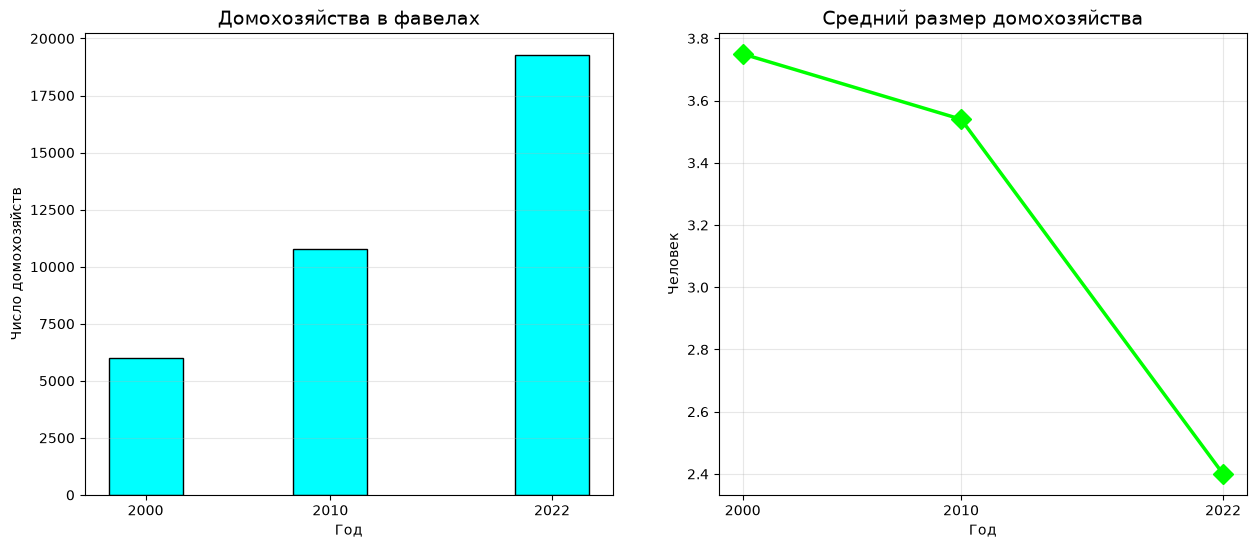

In [113]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
axes[0].bar(anos, dom, color='cyan', edgecolor='black', width=4)
axes[0].set_title('Домохозяйства в фавелах', fontsize=14)
axes[0].set_xlabel('Год')
axes[0].set_ylabel('Число домохозяйств')
axes[0].set_xticks(anos)
axes[0].grid(True, alpha=0.3, axis='y')

axes[1].plot(anos, media_dom, marker='D', color='lime', linewidth=2.5, markersize=10)
axes[1].set_title('Средний размер домохозяйства', fontsize=14)
axes[1].set_xlabel('Год')
axes[1].set_ylabel('Человек')
axes[1].set_xticks(anos)
axes[1].grid(True, alpha=0.3)
plt.savefig('santos-favelas-port-analysis/output/fav_trend.png', dpi=300, bbox_inches='tight')

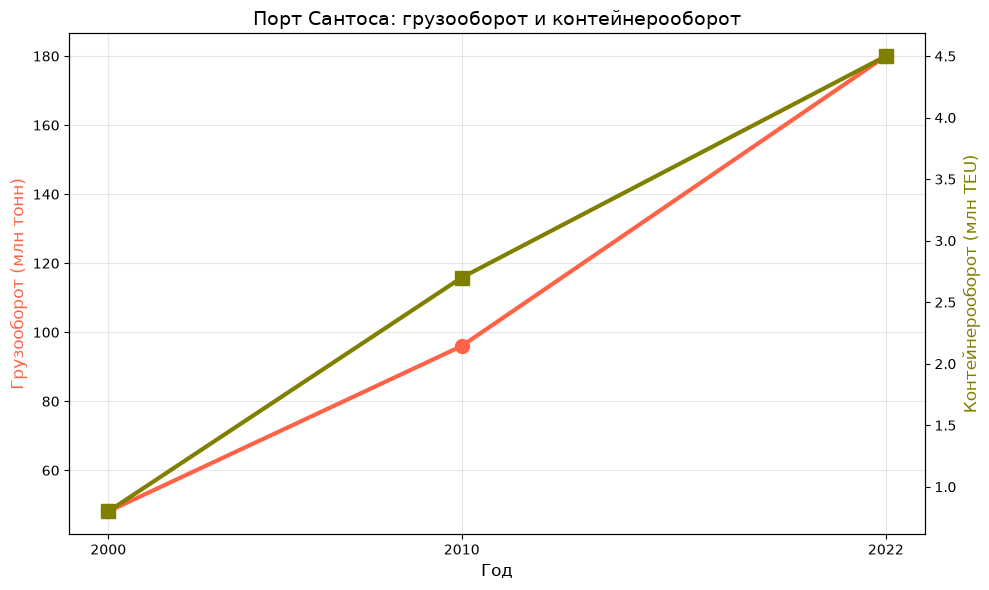

In [114]:
fig, ax1 = plt.subplots(figsize=(10, 6))

ax1.plot(anos, carga, marker='o', color='tomato', linewidth=3, markersize=10)
ax1.set_xlabel('Год', fontsize=12)
ax1.set_ylabel('Грузооборот (млн тонн)', color='tomato', fontsize=12)
ax1.tick_params(axis='y', labelcolor='black')
ax1.set_xticks(anos)
ax1.grid(True, alpha=0.3)


ax2 = ax1.twinx()  
ax2.plot(anos, cont, marker='s', color='olive', linewidth=3, markersize=10)
ax2.set_ylabel('Контейнерооборот (млн TEU)', color='olive', fontsize=12)
ax2.tick_params(axis='y', labelcolor='black')
plt.title('Порт Сантоса: грузооборот и контейнерооборот', fontsize=14)
plt.tight_layout()
plt.savefig('santos-favelas-port-analysis/output/port_trend.png', dpi=300, bbox_inches='tight')

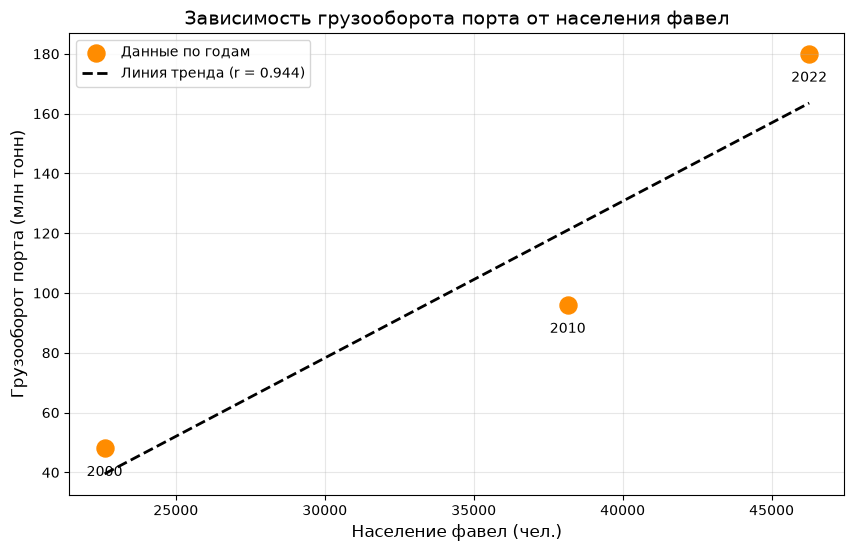

In [115]:
r = np.corrcoef(pop, carga)[0, 1]

slope, intercept = np.polyfit(pop, carga, 1)

plt.figure(figsize=(10, 6))

plt.scatter(pop, carga, color='darkorange', s=150,  label='Данные по годам')


plt.plot(pop, slope * pop + intercept, color='black', linestyle='--', linewidth=2, 
         label=f'Линия тренда (r = {r:.3f})')


for i in range(len(anos)):
    plt.annotate(f'{int(anos[i])}', (pop[i], carga[i]), 
                 textcoords="offset points", xytext=(-13, -20), fontsize=10)

plt.title('Зависимость грузооборота порта от населения фавел', fontsize=14)
plt.xlabel('Население фавел (чел.)', fontsize=12)
plt.ylabel('Грузооборот порта (млн тонн)', fontsize=12)
plt.legend(fontsize=10)
plt.grid(True, alpha=0.3)
plt.savefig('santos-favelas-port-analysis/output/zav_trend.png', dpi=300, bbox_inches='tight')

## Визуализация, ограничения метода и пространственный анализ
В проекте построены графики динамики и график зависимости с линией тренда, показывающие высокую корреляцию (r = 0.94). Однако в реальности корреляция не всегда означает причинно-следственную связь. 

Городская среда неоднородна, чтобы понять реальные причины процессов, необходимо смотреть не только на графики, но и на пространственное размещение объектов. 
В случае Сантуса порт несет разные последствия для пространсвенной динамике города, проявляясь в каждом районе по-своему:
- В районе **Праинья** порт расширяется вглубь города, вытесняя жилье.
- В районе **Сабо** пространственная фиксация контейнерного кластера блокирует развитие общественных пространств.
- В районе **Валонгу** точечный редевелопмент на берегу привел к джентрификации и вытеснению бедных слоев.

Таким образом, количественный анализ дополняется качественным пространственным исследованием. Графики показывают общий тренд, но реальные конфликты и уникальность каждого района определяются его пространственным положением, историей застройки и доступом к ресурсам.